# Chapter 8 — 네트워크/웹 로그 데이터의 이해 (실습)

## 실습 목표
1. CICIDS2017 합성 부분집합의 열·자료형·결측치 진단
2. 라벨별 통계 비교 (groupby)
3. pivot_table 로 라벨 × 포트 매트릭스
4. 언더샘플링·오버샘플링 분포 비교

In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

In [2]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q pandas
# !pip install -q numpy
# !pip install -q matplotlib

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

def make_rows(n, label, dur, pkts, syn, ports):
    return pd.DataFrame({
        'Source IP': rng.choice([f'10.0.0.{i}' for i in range(1,50)], size=n),
        'Destination Port': rng.choice(ports, size=n),
        'Flow Duration': rng.uniform(*dur, size=n),
        'Total Fwd Packets': rng.integers(*pkts, size=n),
        'SYN Flag Count': rng.uniform(*syn, size=n),
        'Protocol': rng.choice([6, 17], size=n, p=[0.85, 0.15]),  # 6=TCP, 17=UDP
        'Label': label,
    })

df = pd.concat([
    make_rows(16000, 'BENIGN',   (1000, 1_000_000), (5, 100),    (0, 0.05),  [80, 443, 53, 22]),
    make_rows( 2300, 'DDoS',     (10, 5000),         (500, 5000), (0.4, 0.7), [80, 443]),
    make_rows( 1200, 'PortScan', (1, 200),           (1, 5),      (0.85, 1.0), list(range(1, 1024))),
], ignore_index=True).sample(frac=1, random_state=0).reset_index(drop=True)

# inf 가 있는 컬럼 시뮬레이션 (CICIDS2017 의 Flow Bytes/s 같은 컬럼)
df['Flow Bytes/s'] = np.where(df['Flow Duration'] < 0.001, np.inf, 1000 / df['Flow Duration'].clip(lower=1e-6))
print(f'shape: {df.shape}')
df.head()

shape: (19500, 8)


,Source IP,Destination Port,Flow Duration,Total Fwd Packets,SYN Flag Count,Protocol,Label,Flow Bytes/s
0,10.0.0.35,80,48068.615060,77,0.018195,6,BENIGN,0.020804
1,10.0.0.28,53,961721.752453,30,0.030678,17,BENIGN,0.001040
2,10.0.0.10,443,446554.504113,10,0.017566,17,BENIGN,0.002239
3,10.0.0.45,206,20.779898,1,0.940299,6,PortScan,48.123432
4,10.0.0.39,80,757.317465,2225,0.661653,6,DDoS,1.320450


---
## Step 1. 진단 — 컬럼·dtype·결측·inf

In [4]:
print('--- dtype ---')
print(df.dtypes)
print('\n--- 결측치 ---')
print(df.isna().sum())

inf_cols = df.columns[(df == np.inf).any() | (df == -np.inf).any()].tolist()
print(f'\n--- inf 가 있는 컬럼 ---\n{inf_cols}')
n_inf = int(np.isinf(df['Flow Bytes/s']).sum())
print(f'Flow Bytes/s 의 inf 개수: {n_inf}')

--- dtype ---
Source IP                str
Destination Port       int64
Flow Duration        float64
Total Fwd Packets      int64
SYN Flag Count       float64
Protocol               int64
Label                    str
Flow Bytes/s         float64
dtype: object

--- 결측치 ---
Source IP            0
Destination Port     0
Flow Duration        0
Total Fwd Packets    0
SYN Flag Count       0
Protocol             0
Label                0
Flow Bytes/s         0
dtype: int64

--- inf 가 있는 컬럼 ---
[]
Flow Bytes/s 의 inf 개수: 0


In [5]:
# inf → NaN 변환
df = df.replace([np.inf, -np.inf], np.nan)
print(f'변환 후 NaN: {df.isna().sum().sum()}')

변환 후 NaN: 0


---
## Step 2. 라벨별 통계

In [6]:
stats = df.groupby('Label').agg(
    n_flows=('Label', 'count'),
    mean_pkts=('Total Fwd Packets', 'mean'),
    mean_dur=('Flow Duration', 'mean'),
    mean_syn=('SYN Flag Count', 'mean'),
).round(2)
stats

,n_flows,mean_pkts,mean_dur,mean_syn
Label,,,,
BENIGN,16000,52.00,503384.46,0.02
DDoS,2300,2743.44,2531.11,0.55
PortScan,1200,2.47,100.58,0.93


---
## Step 3. pivot_table — 라벨 × 포트

In [7]:
top_ports = df['Destination Port'].value_counts().head(10).index.tolist()
pt = df[df['Destination Port'].isin(top_ports)].pivot_table(
    index='Destination Port', columns='Label', values='Flow Duration',
    aggfunc='count', fill_value=0
)
pt

Label,BENIGN,DDoS,PortScan
Destination Port,,,
22,4022,0,3
53,4023,0,1
80,4044,1158,1
192,0,0,5
443,3911,1142,1
494,0,0,4
518,0,0,5
528,0,0,5
734,0,0,4


---
## Step 4. 언더샘플링 vs 오버샘플링

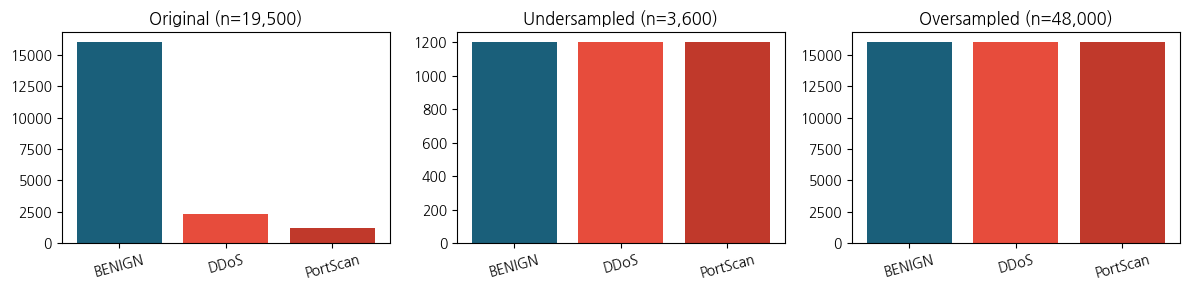

In [8]:
# 언더샘플링 — 다수 클래스를 최소 클래스 수에 맞춤
min_count = df['Label'].value_counts().min()
under = pd.concat([
    g.sample(n=min_count, random_state=0) for _, g in df.groupby('Label')
]).reset_index(drop=True)

# 오버샘플링 — 소수 클래스를 다수 클래스 수에 맞춤 (단순 복원추출)
max_count = df['Label'].value_counts().max()
over = pd.concat([
    g.sample(n=max_count, replace=True, random_state=0) for _, g in df.groupby('Label')
]).reset_index(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (title, d) in zip(axes, [('Original', df), ('Undersampled', under), ('Oversampled', over)]):
    counts = d['Label'].value_counts()
    ax.bar(counts.index, counts.values, color=['#1a5f7a', '#e74c3c', '#c0392b'])
    ax.set_title(f'{title} (n={len(d):,})')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

---
## 정리

- 보안 로그는 결측·inf·불균형이 거의 항상 존재 — 사전 진단이 필수.
- pivot_table 로 라벨 × 다른 차원의 분포를 한 번에 본다.
- 언더/오버샘플링은 단순하지만 매우 효과적인 첫 대응책.
- ch09 에서 본격 전처리(결측·이상·정규화·인코딩)로 들어간다.